# Week 5 — Deep Learning Application in Data Science
## Neural Network for Bank Term-Deposit Subscription Prediction

This notebook builds a feed-forward neural network with TensorFlow/Keras. It uses the same realistic pre-call prediction point as Week 4, so `duration` is excluded. The target is imbalanced; training uses class weights and evaluation emphasizes precision, recall, F1, ROC-AUC and PR-AUC.


In [1]:
# In Google Colab, TensorFlow is typically preinstalled. If needed, uncomment:
# %pip install -q tensorflow

import io, zipfile, urllib.request, warnings, os
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.metrics import (classification_report, confusion_matrix, ConfusionMatrixDisplay,
    accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
    average_precision_score, RocCurveDisplay, PrecisionRecallDisplay)
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
sns.set_theme(style="whitegrid")
tf.keras.utils.set_random_seed(42)
DATA_URL = "https://archive.ics.uci.edu/static/public/222/bank+marketing.zip"

def extract_bank_full(blob):
    with zipfile.ZipFile(io.BytesIO(blob)) as z:
        for n in z.namelist():
            if Path(n).name.lower() == "bank-full.csv": return z.read(n)
        for n in z.namelist():
            if n.lower().endswith(".zip"):
                try:
                    got = extract_bank_full(z.read(n))
                    if got: return got
                except zipfile.BadZipFile: pass
    return None

archive = urllib.request.urlopen(DATA_URL, timeout=60).read()
csv_bytes = extract_bank_full(archive)
if csv_bytes is None: raise FileNotFoundError("bank-full.csv not found")
df = pd.read_csv(io.BytesIO(csv_bytes), sep=";", keep_default_na=False)
df.columns = [c.lower() for c in df.columns]
print(df.shape)


(45211, 17)


## 1. Define leakage-safe inputs and create train, validation and test partitions

The target is 1 for subscription and 0 otherwise. `duration` is excluded because it is only observed after a call. First reserve a stratified test set. Then split the remaining training data into training and validation partitions. Fit preprocessing only on the training partition.


In [2]:
for c in df.select_dtypes(include="object").columns:
    df[c] = df[c].str.strip().str.lower()
y = (df["y"] == "yes").astype("int32")
X = df.drop(columns=["y","duration"]).copy()
X["previously_contacted"] = (X["pdays"] != -1).astype(int)
X["pdays"] = X["pdays"].where(X["pdays"] != -1, np.nan)

numeric = ["age","balance","day","campaign","pdays","previous","previously_contacted"]
categorical = [c for c in X.columns if c not in numeric]
X_train_full, X_test, y_train_full, y_test = train_test_split(
    X,y,test_size=.20,random_state=42,stratify=y)
X_train, X_val, y_train, y_val = train_test_split(
    X_train_full,y_train_full,test_size=.20,random_state=42,stratify=y_train_full)

num_pipe = Pipeline([("impute",SimpleImputer(strategy="median")),("scale",StandardScaler())])
cat_pipe = Pipeline([("impute",SimpleImputer(strategy="most_frequent")),
                     ("onehot",OneHotEncoder(handle_unknown="ignore",sparse_output=False))])
prep = ColumnTransformer([("num",num_pipe,numeric),("cat",cat_pipe,categorical)])
X_train_z = prep.fit_transform(X_train).astype("float32")
X_val_z = prep.transform(X_val).astype("float32")
X_test_z = prep.transform(X_test).astype("float32")
print(X_train_z.shape, X_val_z.shape, X_test_z.shape)


(28934, 51) (7234, 51) (9043, 51)


## 2. Address class imbalance and design the neural network

Class weights make errors on the minority positive class contribute more to the training loss. The network uses dense layers, ReLU activations, batch normalization and dropout. A sigmoid output produces a probability between 0 and 1. The architecture is intentionally moderate because the dataset is tabular and the feature matrix is not an image or sequence.


In [3]:
classes, counts = np.unique(y_train, return_counts=True)
class_weight = {int(c): float(len(y_train)/(len(classes)*n)) for c,n in zip(classes,counts)}
print("Class weights:", class_weight)

model = keras.Sequential([
    layers.Input(shape=(X_train_z.shape[1],)),
    layers.Dense(128, activation="relu"),
    layers.BatchNormalization(),
    layers.Dropout(0.35),
    layers.Dense(64, activation="relu"),
    layers.BatchNormalization(),
    layers.Dropout(0.25),
    layers.Dense(32, activation="relu"),
    layers.Dropout(0.15),
    layers.Dense(1, activation="sigmoid")
])
model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-3),
    loss="binary_crossentropy",
    metrics=[
        keras.metrics.BinaryAccuracy(name="accuracy"),
        keras.metrics.Precision(name="precision"),
        keras.metrics.Recall(name="recall"),
        keras.metrics.AUC(name="roc_auc"),
        keras.metrics.AUC(name="pr_auc", curve="PR")
    ])
model.summary()


Class weights: {0: 0.5662452542173863, 1: 4.273855243722304}


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 128)            │         6,656 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 128)            │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 64)             │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 17,793 (69.50 KB)

 Trainable params: 17,409 (68.00 KB)

 Non-trainable params: 384 (1.50 KB)

## 3. Train with early stopping and learning-rate reduction

Early stopping monitors validation PR-AUC and restores the best weights. ReduceLROnPlateau lowers the learning rate when validation performance stops improving. These controls help reduce overfitting and wasted training.


In [4]:
callbacks = [
    keras.callbacks.EarlyStopping(monitor="val_pr_auc", mode="max", patience=8,
                                  restore_best_weights=True, verbose=1),
    keras.callbacks.ReduceLROnPlateau(monitor="val_pr_auc", mode="max", factor=.5,
                                      patience=3, min_lr=1e-5, verbose=1)
]
history = model.fit(
    X_train_z, y_train,
    validation_data=(X_val_z,y_val),
    epochs=100, batch_size=256,
    class_weight=class_weight,
    callbacks=callbacks,
    verbose=1
)


Epoch 1/100
114/114 ━━━━━━━━━━━━━━━━━━━━ 7s 24ms/step - accuracy: 0.6047 - loss: 0.6872 - pr_auc: 0.2221 - precision: 0.1744 - recall: 0.6369 - roc_auc: 0.6609 - val_accuracy: 0.8575 - val_loss: 0.5414 - val_pr_auc: 0.3597 - val_precision: 0.3957 - val_recall: 0.4149 - val_roc_auc: 0.7532 - learning_rate: 0.0010
Epoch 2/100
114/114 ━━━━━━━━━━━━━━━━━━━━ 3s 9ms/step - accuracy: 0.6875 - loss: 0.6182 - pr_auc: 0.3054 - precision: 0.2167 - recall: 0.6393 - roc_auc: 0.7265 - val_accuracy: 0.8409 - val_loss: 0.4931 - val_pr_auc: 0.3999 - val_precision: 0.3711 - val_recall: 0.5189 - val_roc_auc: 0.7735 - learning_rate: 0.0010
Epoch 3/100
114/114 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - accuracy: 0.7183 - loss: 0.5963 - pr_auc: 0.3421 - precision: 0.2397 - recall: 0.6482 - roc_auc: 0.7469 - val_accuracy: 0.8262 - val_loss: 0.4831 - val_pr_auc: 0.4195 - val_precision: 0.3497 - val_recall: 0.5650 - val_roc_auc: 0.7824 - learning_rate: 0.0010
Epoch 4/100
114/114 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - accur

## 4. Training curves and overfitting diagnosis

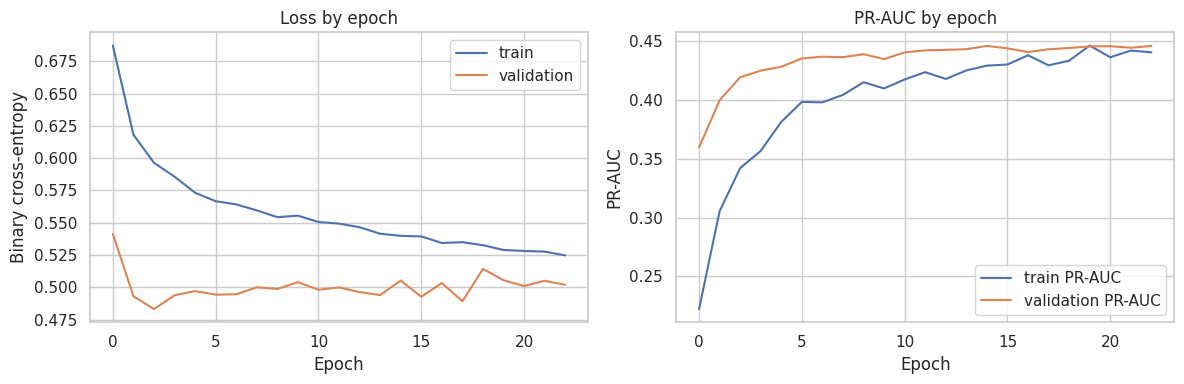

In [5]:
hist = pd.DataFrame(history.history)
fig, axes = plt.subplots(1,2,figsize=(12,4))
axes[0].plot(hist["loss"],label="train"); axes[0].plot(hist["val_loss"],label="validation")
axes[0].set(title="Loss by epoch",xlabel="Epoch",ylabel="Binary cross-entropy"); axes[0].legend()
axes[1].plot(hist["pr_auc"],label="train PR-AUC"); axes[1].plot(hist["val_pr_auc"],label="validation PR-AUC")
axes[1].set(title="PR-AUC by epoch",xlabel="Epoch",ylabel="PR-AUC"); axes[1].legend()
plt.tight_layout(); plt.show()


## 5. Held-out test evaluation

The final test set is evaluated once after model and training decisions are complete. The default probability threshold is 0.50. For an operational decision, select a threshold on validation data to reflect campaign capacity and the relative cost of false positives and false negatives.


,test_score
accuracy,0.8019
precision,0.3225
recall,0.6295
f1,0.4265
roc_auc,0.7873
pr_auc,0.4395


              precision    recall  f1-score   support

          no       0.94      0.82      0.88      7985
         yes       0.32      0.63      0.43      1058

    accuracy                           0.80      9043
   macro avg       0.63      0.73      0.65      9043
weighted avg       0.87      0.80      0.83      9043



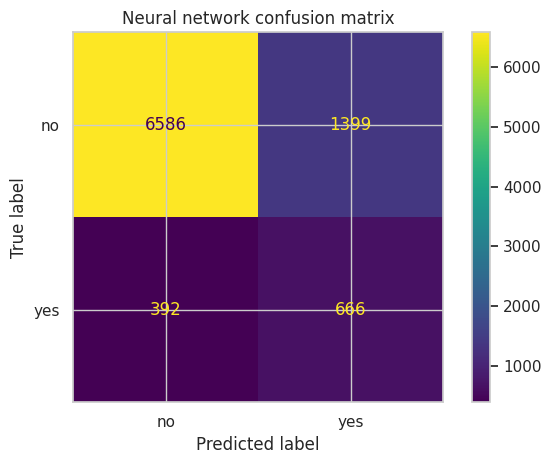

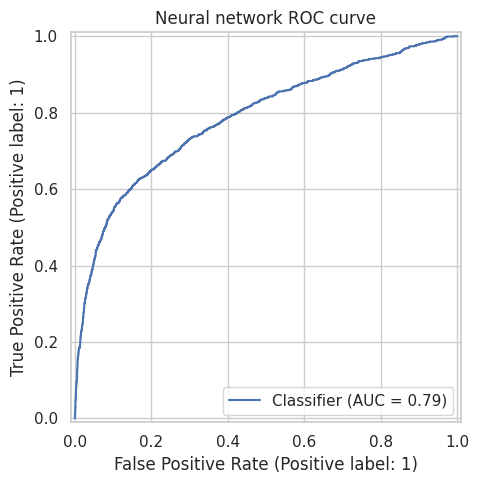

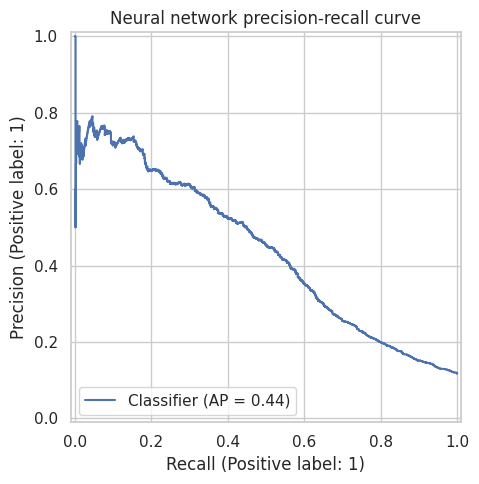

In [6]:
test_prob = model.predict(X_test_z, verbose=0).ravel()
test_pred = (test_prob >= .50).astype(int)
metrics = {
    "accuracy": accuracy_score(y_test,test_pred),
    "precision": precision_score(y_test,test_pred,zero_division=0),
    "recall": recall_score(y_test,test_pred,zero_division=0),
    "f1": f1_score(y_test,test_pred,zero_division=0),
    "roc_auc": roc_auc_score(y_test,test_prob),
    "pr_auc": average_precision_score(y_test,test_prob)
}
display(pd.Series(metrics,name="test_score").to_frame().round(4))
print(classification_report(y_test,test_pred,target_names=["no","yes"],zero_division=0))
ConfusionMatrixDisplay.from_predictions(y_test,test_pred,display_labels=["no","yes"])
plt.title("Neural network confusion matrix"); plt.tight_layout(); plt.show()

fig, ax = plt.subplots(figsize=(7,5))
RocCurveDisplay.from_predictions(y_test,test_prob,ax=ax)
plt.title("Neural network ROC curve"); plt.tight_layout(); plt.show()
fig, ax = plt.subplots(figsize=(7,5))
PrecisionRecallDisplay.from_predictions(y_test,test_prob,ax=ax)
plt.title("Neural network precision-recall curve"); plt.tight_layout(); plt.show()


## 6. Critical analysis and limitations

A tabular neural network is a useful deep-learning implementation but is not guaranteed to outperform gradient-boosted trees or a well-calibrated logistic model on structured data. The network depends on the feature representation, class weights, architecture, learning rate, regularization and random seed. The test metrics should be compared with Week 4 under the same split and feature policy where possible.

The UCI data is historical and the class distribution is imbalanced. Group-based error rates and probability calibration should be assessed before deployment. A model that predicts subscription is not automatically a causal tool for deciding whom to contact. `duration` remains excluded from the pre-call model, preventing leakage from information observed after a call begins.


In [7]:
model.save("bank_marketing_neural_network.keras")
print("Saved bank_marketing_neural_network.keras")


Saved bank_marketing_neural_network.keras
